# Timeline indices — what each one measures, and what it hides

The Explain-mode timeline has to turn a **(29040 nodes x 83 components)** error field into
**one number per timestep**. There is no single right way to do that: you choose an order in
which to collapse the two axes, and different orders give genuinely different timelines.

This notebook defines the three indices we care about, plots each over August 2020, and marks
Hurricane Laura's peak-error timestep (**27 Aug 12:00 UTC**) on every one — so it is visible at
a glance which index surfaces the event and which buries it.

Notation, for one timestep:

$$e_{n,c} = \left| \hat{x}_{n,c} - x_{n,c} \right| \qquad n = \text{node},\ c = \text{component (var@level)}$$

All errors are in the model's **normalised** space (zero mean, unit std per variable), so
components are comparable without unit conversion.

Everything here reads the precomputed `*_timeline_errors.npy` — **no inference runs.**


## 0. Setup

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NPY  = ROOT / "backend" / "data" / "paper_checkpoints" / "graphcast_scripted_timeline_errors.npy"

d = np.load(NPY, allow_pickle=True).item()

ts       = np.array(d["timestamps"], dtype="datetime64[s]")   # (T,)
rmse     = d["rmse"].astype(float)                            # (T,)   mean over nodes AND vars
rmse_max = d["rmse_max"].astype(float)                        # (T,)   max over nodes of per-node RMSE
cm       = d["comp_max"].astype(float)                        # (T,83) max over nodes, per component

vn, lv, na = list(d["var_names"]), list(d["levels"]), int(d["n_atm"])
COLS = [f"{v}@{l}" for v in vn[:na] for l in lv] + list(vn[na:])
assert len(COLS) == cm.shape[1]

AUG   = np.where((ts >= np.datetime64("2020-08-01")) & (ts < np.datetime64("2020-09-01")))[0]
LAURA = int(np.where(ts == np.datetime64("2020-08-27T12:00:00"))[0][0])

print(f"{len(ts)} timesteps  {ts[0]} -> {ts[-1]}")
print(f"{len(AUG)} in August 2020 | Laura peak = {ts[LAURA]} (index {LAURA})")
print(f"{len(COLS)} components")

1503 timesteps  2020-01-01T06:00:00 -> 2021-01-10T18:00:00
124 in August 2020 | Laura peak = 2020-08-27T12:00:00 (index 957)
83 components


In [2]:

# --- restrained house style; colours are the project's semantic palette -------
INK, MUTED, GRIDC = "#2b3038", "#767d89", "#dfe2e6"
HI, ALT = "#C85878", "#3AACBE"          # violation.above / explain.t12h

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
    "axes.edgecolor": GRIDC, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
})

def rank_of(series, i=LAURA):
    """(August rank, August N, full-test-set rank, full N) for timestep i under `series`."""
    return (int((series[AUG] > series[i]).sum()) + 1, len(AUG),
            int((series > series[i]).sum()) + 1, len(series))

def _fmt(v):
    """Enough significant figures for the series' own scale."""
    return f"{v:.3f}" if abs(v) < 1 else (f"{v:.1f}" if abs(v) < 100 else f"{v:.0f}")

def panel(ax, series, title, ylab, winner=None):
    """One index over August. Thin line, Laura marked, August max direct-labelled.

    Labels are placed on whichever side keeps them inside the axes, so nothing
    overflows the right edge or collides with the trace.
    """
    x, y = ts[AUG].astype("datetime64[s]").astype(object), series[AUG]
    ax.plot(x, y, lw=1.6, color=INK, solid_capstyle="round", zorder=2)

    span = (AUG[-1] - AUG[0]) or 1

    # --- Laura: dashed rule + dot, label pushed left (Laura sits near the right edge)
    xl, yl = ts[LAURA].astype(object), series[LAURA]
    ax.axvline(xl, color=HI, lw=1.0, ls=(0, (3, 3)), zorder=1)
    ax.plot([xl], [yl], "o", ms=8, mfc=HI, mec="white", mew=1.6, zorder=4)
    ar, an, fr, fn = rank_of(series)

    # --- August maximum, marked and labelled on whichever side has room
    j = int(np.argmax(y)); xj = ts[AUG[j]].astype(object)
    ax.plot([xj], [y[j]], "o", ms=7, mfc="none", mec=ALT, mew=1.8, zorder=4)
    right = (AUG[j] - AUG[0]) / span > 0.6
    lab = f"Aug max {_fmt(y[j])}" + (f"\n{winner[AUG[j]]}" if winner is not None else "")
    ax.annotate(lab, (xj, y[j]), textcoords="offset points",
                xytext=(-11, -4) if right else (10, -4),
                fontsize=7.5, color=ALT, ha="right" if right else "left",
                va="top", zorder=5)

    ax.set_title(title, loc="left", color=INK, fontweight="medium")
    # Laura's readout lives in the right-hand title, outside the axes, so it can
    # never collide with a dense trace.
    ax.set_title(f"Laura 27 Aug 12Z · {_fmt(yl)} · Aug #{ar}/{an} · year #{fr}/{fn}",
                 loc="right", fontsize=7.5, color=HI)
    ax.set_ylabel(ylab, fontsize=8)
    ax.grid(alpha=.30, lw=.5, color=GRIDC)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.margins(x=.03, y=.16)          # headroom so labels stay inside the axes
    return ax

WINNER = np.array(COLS, dtype=object)[cm.argmax(1)]   # dominant component per timestep
print("style ready")

style ready


---
## 1. Mean RMSE — *average over space and variables*

$$\mathrm{I}_1(t) = \sqrt{\frac{1}{N C}\sum_{n}\sum_{c} e_{n,c}^2}$$

Collapse **both** axes by averaging. This is the classic skill score: one number saying
"how wrong was the model overall at this timestep".

**What it is good for:** seasonal cycle, regime changes, comparing two models.
**What it hides:** everything local. A hurricane occupies a handful of the 29 040 nodes, so
averaging over all of them dilutes it into nothing — the storm cannot move this number.


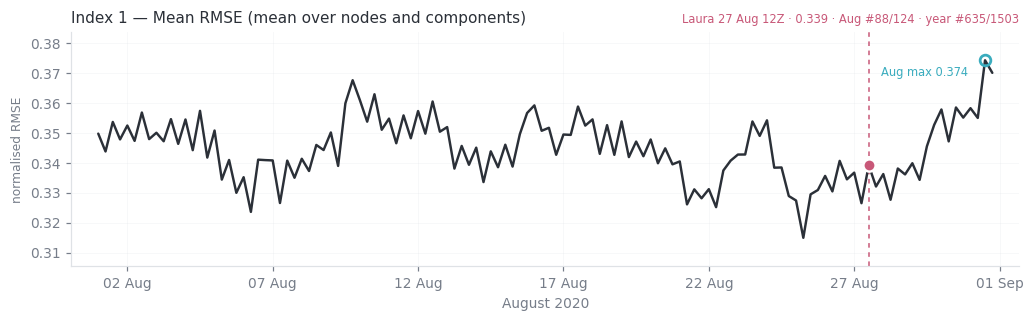

Laura 27 Aug 12Z: value 0.339 | August rank 88/124 | test-set rank 635/1503


In [3]:

fig, ax = plt.subplots(figsize=(9.5, 3.0))
panel(ax, rmse, "Index 1 — Mean RMSE (mean over nodes and components)", "normalised RMSE")
ax.set_xlabel("August 2020")
plt.tight_layout(); plt.show()

ar, an, fr, fn = rank_of(rmse)
print(f"Laura 27 Aug 12Z: value {rmse[LAURA]:.3f} | August rank {ar}/{an} | test-set rank {fr}/{fn}")

---
## 2. Max RMSE — *maximum over space*

"Maximum" is ambiguous, because it matters **whether you average over variables before or after
taking the max**. The two readings give different timelines, and conflating them is the single
easiest mistake to make here.

**2a — max over space, mean over variables** (`rmse_max` in the file):

$$\mathrm{I}_{2a}(t) = \max_{n} \sqrt{\frac{1}{C}\sum_c e_{n,c}^2}$$

Find the single worst *node*, where "worst" is its all-variable RMSE. It is tempting to assume
the average over 83 components dilutes a few catastrophic fields — it does **not**, because RMS is
dominated by its largest terms. At Laura's node the 7 worst components alone give
$\sqrt{\sum_{7} e^2 / 83} = 5.38$ of the actual 5.64. The small errors contribute almost nothing.

**2b — max over space AND variables** (`comp_max.max(axis=1)`, the UI's *Var max*):

$$\mathrm{I}_{2b}(t) = \max_{n,c} e_{n,c}$$

Nothing is averaged at all. This is the largest single error anywhere on the planet in any field.

> **The catch with 2b:** it is a *max of maxima*, so it always reports whichever component has
> the fattest tail in normalised space — not whichever timestep is interesting. In practice
> that is stratospheric vertical velocity almost every time.

Because of the RMS property above, **2a turns out to be the most event-sensitive of the four
indices** — it keeps the big errors *and* requires them to co-occur at a single node, which is
exactly what a storm does.


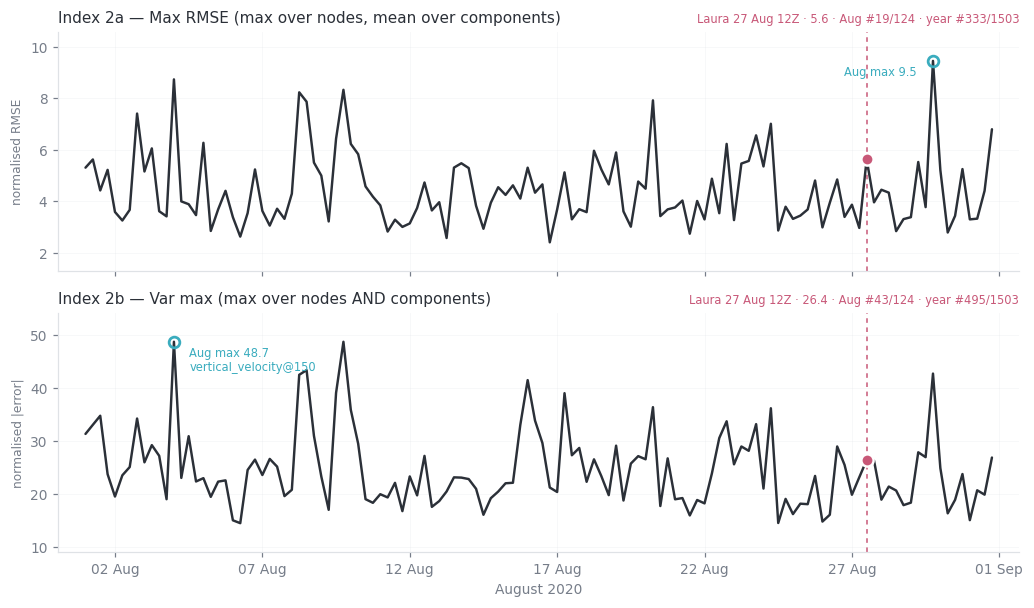

2a  max-node RMSE      Laura     5.64 | August #19/124 | test set #333/1503
2b  Var max            Laura    26.40 | August #43/124 | test set #495/1503


In [4]:

fig, axes = plt.subplots(2, 1, figsize=(9.5, 5.6), sharex=True)
panel(axes[0], rmse_max, "Index 2a — Max RMSE (max over nodes, mean over components)", "normalised RMSE")
panel(axes[1], cm.max(1), "Index 2b — Var max (max over nodes AND components)", "normalised |error|",
      winner=WINNER)
axes[1].set_xlabel("August 2020")
plt.tight_layout(); plt.show()

for name, s in [("2a  max-node RMSE", rmse_max), ("2b  Var max", cm.max(1))]:
    ar, an, fr, fn = rank_of(s)
    print(f"{name:22s} Laura {s[LAURA]:8.2f} | August #{ar}/{an} | test set #{fr}/{fn}")

In [5]:

# Which component wins Index 2b, over the whole test set? This is the tail problem, counted.
from collections import Counter
tot = Counter(WINNER)
print("Component that drives 'Var max', share of all 1503 timesteps:\n")
for c, n in tot.most_common(8):
    print(f"  {c:28s}{n:5d}   {100*n/len(WINNER):5.1f}%")

Component that drives 'Var max', share of all 1503 timesteps:

  vertical_velocity@50          410    27.3%
  vertical_velocity@200         344    22.9%
  vertical_velocity@150         229    15.2%
  total_precipitation_6hr       174    11.6%
  vertical_velocity@250         144     9.6%
  vertical_velocity@100          72     4.8%
  vertical_velocity@300          41     2.7%
  vertical_velocity@600          27     1.8%


---
## 3. Self-normalised max — *how unusual is this error, for this component?*

Index 2b is dominated by whichever component is *always* large. The fix is to score each
component against **its own** typical value before comparing components to each other:

$$\mathrm{I}_3(t) = \max_{c}\ \frac{\displaystyle\max_n e_{n,c}}{\ \mathrm{median}_{t'}\left(\max_n e_{n,c}(t')\right)}$$

The denominator is that component's median peak error **over the full test set**, so it is a
fixed baseline, not something that moves with the window being viewed. A value of 3 means
"this component's peak error is 3x its own normal peak error".

This removes the units problem *and* the fat-tail problem: a component that is large at every
timestep has a large median too, so it scores ~1 and drops out.


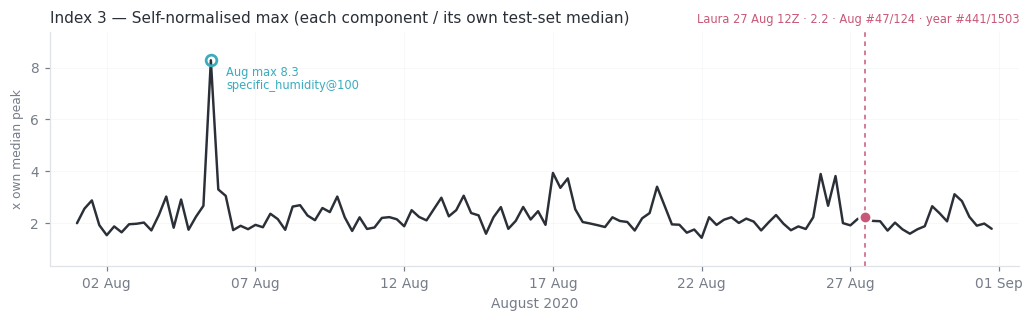

Laura 27 Aug 12Z: value 2.23x | August rank 47/124 | test-set rank 441/1503


In [6]:

BASE = np.median(cm, axis=0)             # per-component baseline, full test set
Z    = cm / BASE                         # (T, 83) "x its own normal peak"
I3   = Z.max(1)
WIN3 = np.array(COLS, dtype=object)[Z.argmax(1)]

fig, ax = plt.subplots(figsize=(9.5, 3.0))
panel(ax, I3, "Index 3 — Self-normalised max (each component / its own test-set median)",
      "x own median peak", winner=WIN3)
ax.set_xlabel("August 2020")
plt.tight_layout(); plt.show()

ar, an, fr, fn = rank_of(I3)
print(f"Laura 27 Aug 12Z: value {I3[LAURA]:.2f}x | August rank {ar}/{an} | test-set rank {fr}/{fn}")

### Does the normalisation actually help?

Yes — *within* a component. Raw magnitude ranks stratospheric `w@50` above Laura's `w@925`;
self-normalised, that flips. But note the last column: once you **fix** the component, the raw
series already puts Laura first in August. The normalisation only earns its keep when you need
to compare *across* components.


In [7]:

print(f"{'component':28s}{'raw':>9s}{'own median':>12s}{'x median':>10s}{'Aug rank (raw)':>16s}")
for c in ["vertical_velocity@925", "total_precipitation_6hr", "vertical_velocity@50",
          "vertical_velocity@150"]:
    j = COLS.index(c); s = cm[:, j]
    ar = int((s[AUG] > s[LAURA]).sum()) + 1
    print(f"{c:28s}{s[LAURA]:9.2f}{BASE[j]:12.2f}{Z[LAURA, j]:10.2f}{ar:>13d}/{len(AUG)}")

component                         raw  own median  x median  Aug rank (raw)
vertical_velocity@925           12.26        6.09      2.01            1/124
total_precipitation_6hr         26.40       14.42      1.83            2/124
vertical_velocity@50            24.44       15.78      1.55           29/124
vertical_velocity@150           24.48       16.08      1.52           19/124


### The catch: `max` over components undoes it

Index 3 takes the max over all 83 components, and that hands the timeline straight back to
whichever component is *most erratic* rather than most anomalous. At Laura's timestep the
winner is `specific_humidity@50` at 2.23x — incidental, nothing to do with the hurricane.
Laura's actual signal, `w@850` at 2.18x, comes second and never gets shown.


In [8]:

print("Index 3 at Laura — what wins the max over components:")
for j in np.argsort(-Z[LAURA])[:4]:
    print(f"   {COLS[j]:26s}{Z[LAURA, j]:6.2f}x")

print("\nTop-5 August timesteps under Index 3 — the tail just moved to another component:")
for j in AUG[np.argsort(-I3[AUG])[:5]]:
    print(f"   {str(ts[j])[:16]}  {I3[j]:6.2f}x  ({WIN3[j]})")

print("\nBut FIX the component to w@925, and Laura is August #1 outright:")
s925 = cm[:, COLS.index("vertical_velocity@925")]
for j in AUG[np.argsort(-s925[AUG])[:4]]:
    print(f"   {str(ts[j])[:16]}  {s925[j]:6.2f}" + ("   <== LAURA" if j == LAURA else ""))

Index 3 at Laura — what wins the max over components:
   specific_humidity@50        2.23x
   vertical_velocity@850       2.18x
   geopotential@700            2.07x
   vertical_velocity@925       2.01x

Top-5 August timesteps under Index 3 — the tail just moved to another component:
   2020-08-05T12:00    8.28x  (specific_humidity@100)
   2020-08-17T00:00    3.94x  (specific_humidity@100)
   2020-08-26T00:00    3.90x  (specific_humidity@100)
   2020-08-26T12:00    3.82x  (specific_humidity@100)
   2020-08-17T12:00    3.73x  (specific_humidity@100)

But FIX the component to w@925, and Laura is August #1 outright:
   2020-08-27T12:00   12.26   <== LAURA
   2020-08-09T18:00   11.58
   2020-08-27T18:00    9.25
   2020-08-24T00:00    8.63


---
## 4. Side by side

Same window, same event, four indices. The dashed line is Laura's peak-error timestep in all
four panels.


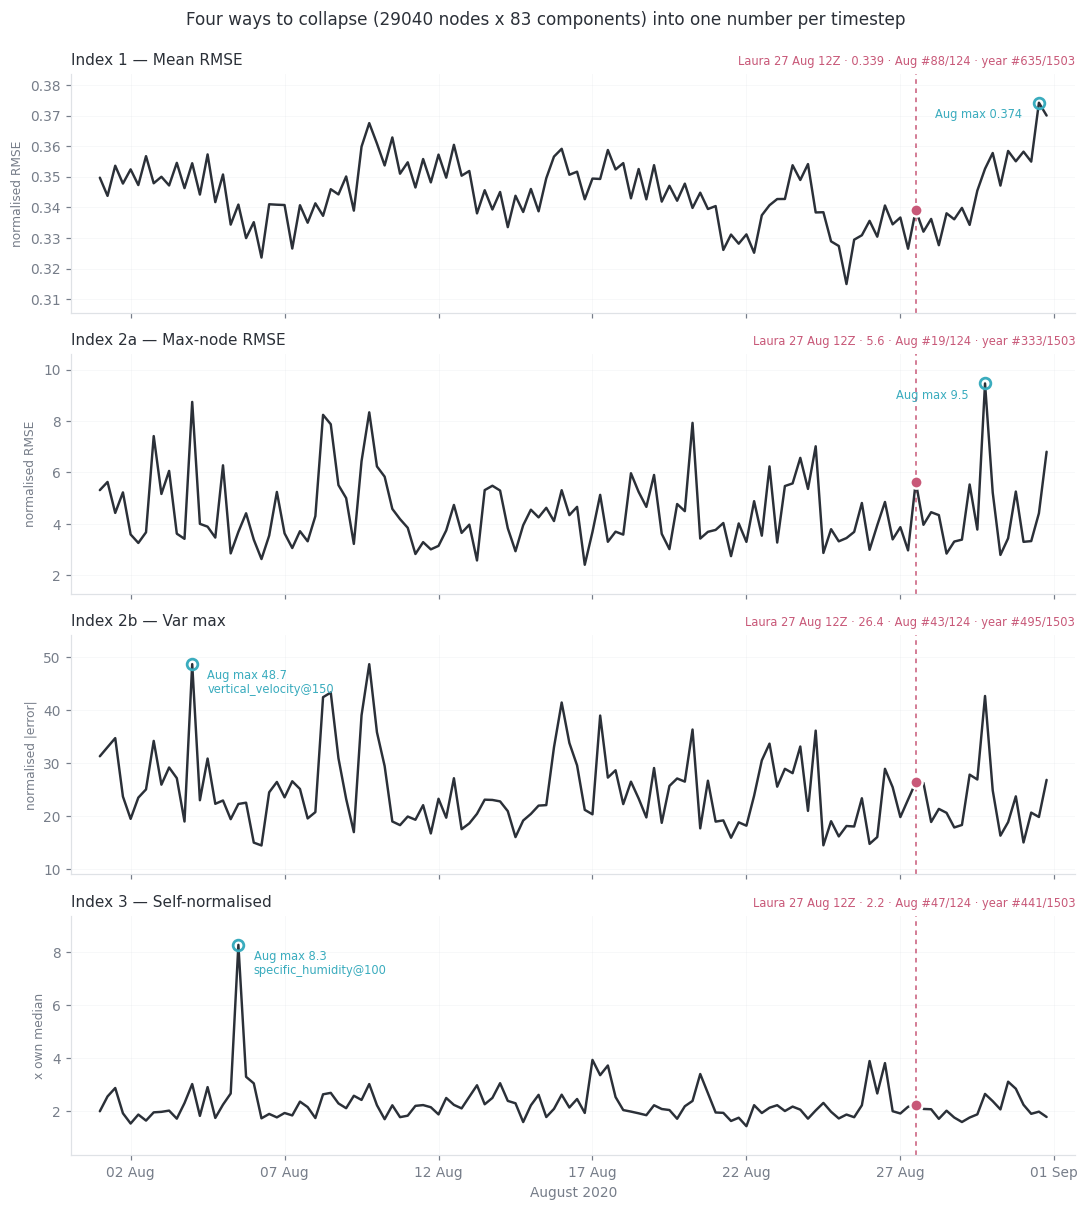

In [9]:

SERIES = [
    (rmse,       "Index 1 — Mean RMSE",        "normalised RMSE",   None),
    (rmse_max,   "Index 2a — Max-node RMSE",   "normalised RMSE",   None),
    (cm.max(1),  "Index 2b — Var max",         "normalised |error|", WINNER),
    (I3,         "Index 3 — Self-normalised",  "x own median",      WIN3),
]

fig, axes = plt.subplots(len(SERIES), 1, figsize=(10, 11), sharex=True)
for ax, (s, t, yl, w) in zip(axes, SERIES):
    panel(ax, s, t, yl, winner=w)
axes[-1].set_xlabel("August 2020")
fig.suptitle("Four ways to collapse (29040 nodes x 83 components) into one number per timestep",
             y=.995, fontsize=11, color=INK)
plt.tight_layout(); plt.show()

## 5. Verdict table

Where Laura's 27 Aug 12:00 timestep ranks under each index — in August, and against the
full 1503-step test set.


In [10]:

print(f"{'index':30s}{'Laura value':>13s}{'Aug rank':>12s}{'test-set rank':>16s}")
print("-" * 71)
for s, t, _, _ in SERIES:
    ar, an, fr, fn = rank_of(s)
    print(f"{t:30s}{s[LAURA]:13.3f}{f'{ar}/{an}':>12s}{f'{fr}/{fn}':>16s}")

index                           Laura value    Aug rank   test-set rank
-----------------------------------------------------------------------
Index 1 — Mean RMSE                   0.339      88/124        635/1503
Index 2a — Max-node RMSE              5.641      19/124        333/1503
Index 2b — Var max                   26.397      43/124        495/1503
Index 3 — Self-normalised             2.232      47/124        441/1503


### Reading the table

- **Index 1 (Mean RMSE)** — Laura is mid-pack (Aug #88/124). Expected, not a defect: averaging
  over 29 040 nodes is *designed* to be insensitive to a few-cell event. Use it for model
  comparison, never for event spotting.
- **Index 2a (Max-node RMSE)** — **the best of the four** (Aug #19/124, year #333/1503), which is
  the opposite of what you would guess. Averaging over components does not dilute, because RMS is
  carried by its largest terms; and requiring many components to be bad *at the same node* is a
  good description of a storm.
- **Index 2b (Var max)** — reports Laura's value **exactly** (26.40, precipitation), but a third of
  August scores higher, essentially all on stratospheric vertical velocity. The number is honest;
  the ranking is not discriminative.
- **Index 3 (Self-normalised)** — fixes the `w@50` problem and then re-creates it with
  `specific_humidity@100`. Taking a max over 83 components always finds the most erratic one.
  Per-component it is a genuine improvement; as a single global scalar it is not.

**The honest conclusion:** none of the four surfaces Hurricane Laura on its own. They are *global*
reductions and Laura is a *local* event — the information is destroyed by the reduction before any
ranking happens. Two directions do work, and neither is a better scalar:

1. **Fix the component.** With the target set to `vertical_velocity@925`, the raw series puts
   Laura at **August #1/124** with no normalisation at all. The UI already has this selector.
2. **Restrict the max to the map viewport.** A spatial filter rather than a smarter number. The
   precomputed file cannot support this today — it stores the global max per component but not the
   node where that max occurred. Storing that argmax node (one int per component per timestep,
   roughly the same file size) would make "worst error in view" possible.


---
# 6. Three more indices — these need the model

Everything above read the precomputed `.npy`. The next three indices cannot: they need the
**full error map** at each timestep, not just its per-component maximum. One August pass over
the model (~90 s on CPU) produces all three.


In [11]:

import os, sys, time, warnings
os.environ["DATA_ROOT"]       = str(ROOT / "backend" / "data")
os.environ["NEURAL_LAM_PATH"] = str(ROOT / "backend" / "neural-lam")
sys.path.insert(0, str(ROOT / "backend" / "src"))
warnings.filterwarnings("ignore")

import torch
from services import inference as inf
inf.DEVICE = "cpu"; DEV = "cpu"

model = inf.load_torchscript(inf.MODEL_PATH, device=DEV)
cache = inf.preload_era5_tensors(inf.FIELDS_ZARR_PATH, device=DEV, lazy=True)
grid  = inf.load_grid(); LAT, LON = grid["lat"], grid["lon"]
ATM, SURF, LEVELS = cache["atm_vars"], cache["surf_vars"], cache["levels"]
assert [f"{v}@{l}" for v in ATM for l in LEVELS] + list(SURF) == COLS, "column layout mismatch"

# --- land-sea mask -----------------------------------------------------------
# grid_features.pt column 4 is ERA5's fractional land-sea mask (0 = sea, 1 = land).
# Identified by inspection: mean 0.337 matches the global land fraction, and it reads
# ~1 over Louisiana / Sahara / Amazon and exactly 0 over open ocean.
gf  = np.asarray(torch.load(ROOT / "backend" / "data" / "era5_datasets" / "static" /
                            "grid_features.pt", map_location="cpu", weights_only=True))
LSM = gf[:, 4]
LAND = np.where(LSM > 0.5)[0]        # "inland"
SEA  = np.where(LSM <= 0.5)[0]       # "outland"
print(f"land nodes {len(LAND)} ({len(LAND)/len(LSM):.1%}) | sea nodes {len(SEA)}")
print(f"Laura node land fraction = {LSM[np.argmin((LAT-31.5)**2 + (((LON+93.0+180)%360)-180)**2)]:.3f}")

def cidx(var, level=None):
    return len(ATM) * len(LEVELS) + list(SURF).index(var) if var in SURF \
        else list(ATM).index(var) * len(LEVELS) + list(LEVELS).index(int(level))

def states(t):
    # (prediction, truth) in PHYSICAL units for one prediction time.
    p = inf.run_inference_cached(model=model, era5_cache=cache, pred_time=t, device=DEV)[0]
    i = inf.resolve_pred_idx(cache, pred_time=t)
    return (inf.denormalize(p).numpy(),
            inf.denormalize(inf.get_era5_normalized_state(cache, i, device=DEV)).numpy())

[inference] Using global TOA normalization from toa_solar_radiation_max.pt
land nodes 9850 (33.9%) | sea nodes 19190
Laura node land fraction = 0.973


In [12]:

# --- one August pass; every model-based index below is derived from it -------
times = [str(t)[:19] for t in inf.get_available_pred_timestamps(cache)]
times = [t for t in times if t[:7] == "2020-08"]

t0 = time.time()
A_TS, A_COH, A_COHNODE, A_LAND, A_SEA, A_LANDC, A_SEAC = [], [], [], [], [], [], []
for n, t in enumerate(times):
    p = inf.run_inference_cached(model=model, era5_cache=cache, pred_time=t, device=DEV)[0].numpy()
    i = inf.resolve_pred_idx(cache, pred_time=t)
    E = np.abs(p - inf.get_era5_normalized_state(cache, i, device=DEV).numpy())   # (nodes, 83)

    # Index 4 - coherence: how many components share one argmax node
    cnt = np.bincount(E.argmax(0), minlength=len(LAT))
    k = int(cnt.argmax()); A_COH.append(int(cnt[k])); A_COHNODE.append(k)

    # Indices 5 & 6 - the same 'Var max' statistic, restricted to land / to sea
    el, es = E[LAND], E[SEA]
    jl = np.unravel_index(el.argmax(), el.shape); js = np.unravel_index(es.argmax(), es.shape)
    A_LAND.append(float(el[jl])); A_LANDC.append(COLS[jl[1]])
    A_SEA.append(float(es[js]));  A_SEAC.append(COLS[js[1]])
    A_TS.append(t[:16])
    if n % 25 == 0: print(f"  {n}/{len(times)}  {time.time()-t0:.0f}s", flush=True)

A_TS = np.array(A_TS); A_COH = np.array(A_COH)
A_LAND = np.array(A_LAND); A_SEA = np.array(A_SEA)
A_LANDC = np.array(A_LANDC, dtype=object); A_SEAC = np.array(A_SEAC, dtype=object)
iL = int(np.where(A_TS == "2020-08-27T12:00")[0][0])
print(f"\ndone in {time.time()-t0:.0f}s — {len(A_TS)} timesteps")

def panel_aug(ax, series, title, ylab, winner=None, step=False):
    # Same house style as panel(), for the August-only model-derived series.
    x = np.array(A_TS, dtype="datetime64[s]").astype(object)
    ax.plot(x, series, lw=1.6, color=INK, solid_capstyle="round", zorder=2,
            drawstyle="steps-mid" if step else "default")
    xl, yl = x[iL], series[iL]
    ax.axvline(xl, color=HI, lw=1.0, ls=(0, (3, 3)), zorder=1)
    ax.plot([xl], [yl], "o", ms=8, mfc=HI, mec="white", mew=1.6, zorder=4)
    r = int((series > yl).sum()) + 1
    j = int(np.argmax(series)); xj = x[j]
    ax.plot([xj], [series[j]], "o", ms=7, mfc="none", mec=ALT, mew=1.8, zorder=4)
    right = j / len(series) > 0.6
    lab = f"Aug max {_fmt(series[j])}" + (f"\n{winner[j]}" if winner is not None else "")
    ax.annotate(lab, (xj, series[j]), textcoords="offset points",
                xytext=(-11, -4) if right else (10, -4), fontsize=7.5, color=ALT,
                ha="right" if right else "left", va="top", zorder=5)
    ax.set_title(title, loc="left", color=INK, fontweight="medium")
    ax.set_title(f"Laura 27 Aug 12Z · {_fmt(yl)} · Aug #{r}/{len(series)}",
                 loc="right", fontsize=7.5, color=HI)
    ax.set_ylabel(ylab, fontsize=8); ax.grid(alpha=.30, lw=.5, color=GRIDC)
    ax.set_axisbelow(True); ax.margins(x=.03, y=.16)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    return r

  0/122  2s
  25/122  16s
  50/122  29s
  75/122  43s
  100/122  58s

done in 72s — 122 timesteps


---
## Index 4 — coherence count *(unit-free)*

$$\mathrm{I}_4(t) = \max_n \ \#\left\{c \ :\ \arg\max_{n'} e_{n',c} = n \right\}$$

Count, for each node, how many of the 83 components put their **worst error on Earth** there;
take the largest count. This measures **coherence** — a real physical event breaking many fields
at one place — rather than magnitude.

Two properties make it the only index here that dodges the units problem outright:

1. **A count has no units.** Nothing needs rescaling to be comparable across timesteps.
2. **It is invariant to normalisation.** Since $\arg\max_n (s_c\, e_{n,c}) = \arg\max_n e_{n,c}$
   for any per-component scale $s_c > 0$, σ-space and physical units give the *identical* count.
   There is no normalisation choice to get wrong, because there is no normalisation.


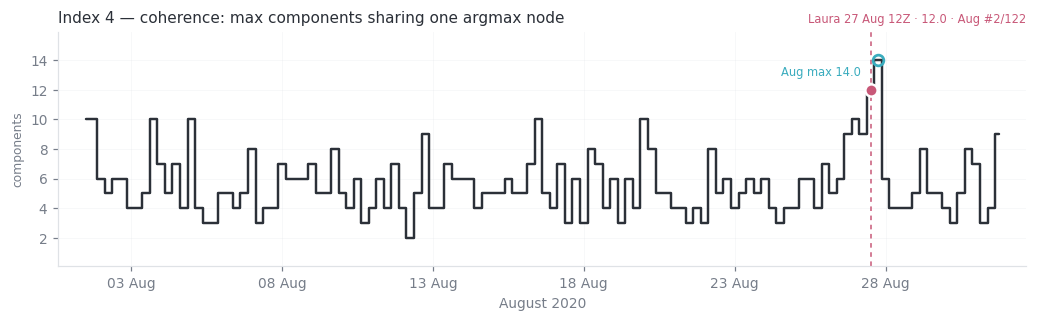

August median 5, mean 5.6

Top-12 August timesteps:
   2020-08-27T18:00   14 components  node ( 31.5,  -93.0)   <== LAURA track
   2020-08-27T12:00   12 components  node ( 31.5,  -93.0)   <== LAURA track
   2020-08-01T12:00   10 components  node (-66.0,  114.0)
   2020-08-27T00:00   10 components  node ( 28.5,  -93.0)   <== LAURA track
   2020-08-20T00:00   10 components  node ( 54.0,  -10.5)
   2020-08-05T00:00   10 components  node (  3.0,   64.5)
   2020-08-03T18:00   10 components  node (-67.5,  141.0)
   2020-08-16T12:00   10 components  node (-45.0,  -70.5)
   2020-08-01T18:00   10 components  node ( -4.5, -175.5)
   2020-08-31T18:00    9 components  node ( -6.0,  162.0)
   2020-08-27T06:00    9 components  node ( 30.0,  -93.0)   <== LAURA track
   2020-08-12T18:00    9 components  node (-66.0, -132.0)


In [13]:

fig, ax = plt.subplots(figsize=(9.5, 3.0))
panel_aug(ax, A_COH, "Index 4 — coherence: max components sharing one argmax node",
          "components", step=True)
ax.set_xlabel("August 2020")
plt.tight_layout(); plt.show()

print(f"August median {np.median(A_COH):.0f}, mean {A_COH.mean():.1f}\n")
print("Top-12 August timesteps:")
for j in np.argsort(-A_COH)[:12]:
    k = A_COHNODE[j]
    laura = abs(LAT[k] - 31.5) < 3.5 and abs(LON[k] + 93.0) < 3.5
    print(f"   {A_TS[j]}  {A_COH[j]:3d} components  node ({LAT[k]:5.1f},{LON[k]:7.1f})"
          + ("   <== LAURA track" if laura else ""))

---
## Indices 5 & 6 — inland max and outland max

The same statistic as Index 2b (max over nodes and components, in σ), but with the error map
**masked to land nodes** and to **sea nodes** respectively:

$$\mathrm{I}_5(t) = \max_{n \in \text{land},\, c} e_{n,c} \qquad
  \mathrm{I}_6(t) = \max_{n \in \text{sea},\, c} e_{n,c}$$

The hope is that masking removes a competing population — e.g. open-ocean tropical convection —
and lets a landfalling storm stand out. Laura's node is 97% land, so it lives in Index 5.


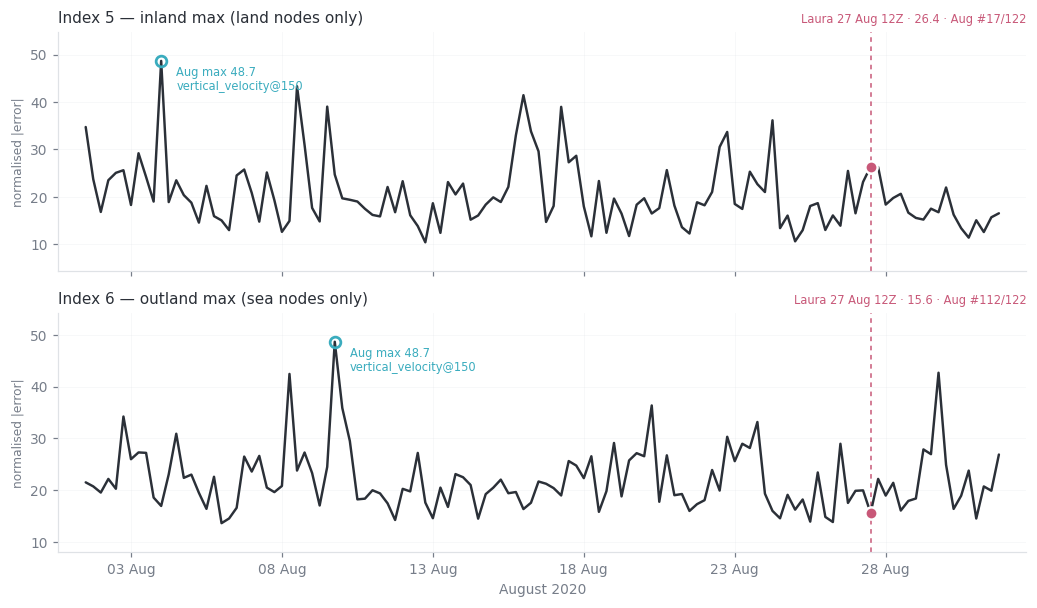

inland   driven by: vertical_velocity@50 61, vertical_velocity@200 13, total_precipitation_6hr 13, vertical_velocity@150 11
outland  driven by: vertical_velocity@50 41, vertical_velocity@200 35, vertical_velocity@150 16, total_precipitation_6hr 15

At Laura 27 Aug 12Z:  inland winner = total_precipitation_6hr (26.40) | outland winner = vertical_velocity@300 (15.56)


In [14]:

fig, axes = plt.subplots(2, 1, figsize=(9.5, 5.6), sharex=True)
panel_aug(axes[0], A_LAND, "Index 5 — inland max (land nodes only)", "normalised |error|",
          winner=A_LANDC)
panel_aug(axes[1], A_SEA,  "Index 6 — outland max (sea nodes only)", "normalised |error|",
          winner=A_SEAC)
axes[1].set_xlabel("August 2020")
plt.tight_layout(); plt.show()

from collections import Counter
for nm, w in [("inland", A_LANDC), ("outland", A_SEAC)]:
    top = ", ".join(f"{c} {n}" for c, n in Counter(w).most_common(4))
    print(f"{nm:8s} driven by: {top}")
print(f"\nAt Laura 27 Aug 12Z:  inland winner = {A_LANDC[iL]} ({A_LAND[iL]:.2f})"
      f" | outland winner = {A_SEAC[iL]} ({A_SEA[iL]:.2f})")

### Verdict on all six

In [15]:

rows = [("1  — Mean RMSE",          rmse[AUG],        None),
        ("2a — Max-node RMSE",      rmse_max[AUG],    None),
        ("2b — Var max",            cm.max(1)[AUG],   None),
        ("3  — Self-normalised",    I3[AUG],          None),
        ("4  — Coherence count",    A_COH,            "unit-free"),
        ("5  — Inland max",         A_LAND,           None),
        ("6  — Outland max",        A_SEA,            None)]
print(f"{'index':26s}{'Laura':>10s}{'August rank':>14s}   note")
print("-" * 68)
for nm, s, note in rows:
    s = np.asarray(s, dtype=float)
    v = s[iL] if len(s) == len(A_TS) else s[int(np.where(AUG == LAURA)[0][0])]
    r = int((s > v).sum()) + 1
    print(f"{nm:26s}{v:10.3f}{f'{r}/{len(s)}':>14s}   {note or ''}")

index                          Laura   August rank   note
--------------------------------------------------------------------
1  — Mean RMSE                 0.339        88/124   
2a — Max-node RMSE             5.641        19/124   
2b — Var max                  26.397        43/124   
3  — Self-normalised           2.232        47/124   
4  — Coherence count          12.000         2/122   unit-free
5  — Inland max               26.397        17/122   
6  — Outland max              15.561       112/122   


---
# 7. Is Laura a *structural* error, or just a missed feature?

The distinction matters for the use case, and it is what shows the node was not cherry-picked.

- A **missed feature** would mean the model failed to produce the storm, or put it somewhere else.
  Its error map would be a **dipole** — too much on one side, too little on the other — and the
  errors would not line up across fields.
- A **structural error** means the storm is present and correctly located, but its *amplitude and
  vertical structure* are wrong. Its error map is a **monopole**, the deficit is systematic through
  the whole column, and many fields break at the same place at once.

The six panels below test exactly that, and none of them depends on having chosen this node
in advance.


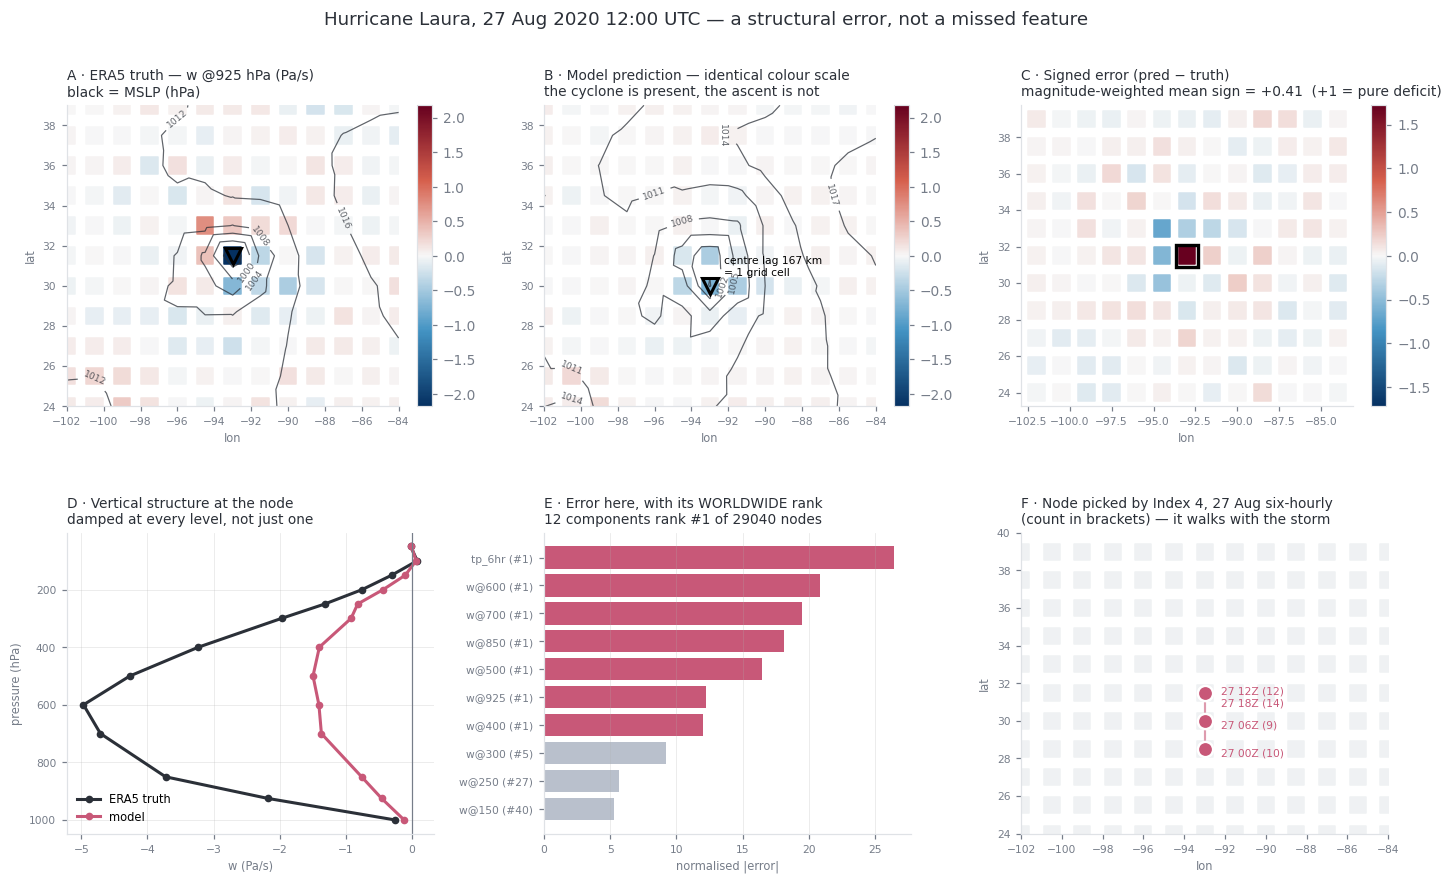

amplitude ratio pred/truth @925 hPa      : 0.21
mean ratio over 400-925 hPa              : 0.30
predicted centre displacement            : 167 km (1 grid cell)
signed error extremes in +/-6deg box     : +1.72 / -0.70 Pa/s
magnitude-weighted mean sign             : +0.41
components ranking #1 worldwide here     : 12


In [16]:

from matplotlib.colors import LinearSegmentedColormap

# project palette: colors.json -> divergingWind
DIV = LinearSegmentedColormap.from_list(
    "divergingWind", ["#053061", "#4393c3", "#f7f7f7", "#d6604d", "#67001f"])
SHORT = {"vertical_velocity": "w", "total_precipitation_6hr": "tp_6hr",
         "specific_humidity": "q", "geopotential": "z", "temperature": "T",
         "mean_sea_level_pressure": "mslp"}
def short(c):
    v, _, l = c.partition("@")
    return f"{SHORT.get(v, v)}@{l}" if l else SHORT.get(v, v)

T12 = "2020-08-27T12:00:00"
K   = int(np.argmin((LAT - 31.5)**2 + (((LON + 93.0 + 180) % 360) - 180)**2))
P, TR = states(T12)
cw, cmsl = cidx("vertical_velocity", 925), cidx("mean_sea_level_pressure")

# tight region so the storm fills the panel (it is only a few cells at 1.5 deg)
reg = np.where((LAT >= 24) & (LAT <= 40) & (LON >= -102) & (LON <= -84))[0]
xs, ys = LON[reg], LAT[reg]
lim = float(np.abs(TR[reg, cw]).max())

kT = reg[int(np.argmin(TR[reg, cmsl]))]; kP = reg[int(np.argmin(P[reg, cmsl]))]
R = 6371.0
p1, p2 = np.radians(LAT[kT]), np.radians(LAT[kP])
a = np.sin((p2-p1)/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(np.radians(LON[kP]-LON[kT])/2)**2
lag_km = 2*R*np.arcsin(np.sqrt(a))

# --- monopole vs dipole -------------------------------------------------------
# A plain |sum e| / sum|e| is swamped by the many near-zero cells around the storm,
# which cancel and drive it to ~0 regardless. Weight by error magnitude instead:
# mono = sum(sign(e) * e^2) / sum(e^2) is the e^2-weighted mean sign, so the cells
# that carry the error decide it. +1 = pure deficit, 0 = balanced dipole.
err = P[:, cw] - TR[:, cw]
box  = np.where((np.abs(LAT - LAT[K]) <= 6) & (np.abs(LON - LON[K]) <= 6))[0]
mono = float((np.sign(err[box]) * err[box]**2).sum() / (err[box]**2).sum())

Efull = np.abs(inf.run_inference_cached(model=model, era5_cache=cache, pred_time=T12,
                                        device=DEV)[0].numpy()
               - inf.get_era5_normalized_state(cache, inf.resolve_pred_idx(cache, pred_time=T12),
                                               device=DEV).numpy())
rank_at_node = sorted([(COLS[c], float(Efull[K, c]),
                        int((Efull[:, c] > Efull[K, c]).sum()) + 1)
                       for c in range(len(COLS))], key=lambda r: -r[1])

fig = plt.figure(figsize=(15.5, 8.6))
gs  = fig.add_gridspec(2, 3, hspace=.42, wspace=.30)

def mapax(ax, vals, title, vlim):
    s = ax.scatter(xs, ys, c=vals, cmap=DIV, vmin=-vlim, vmax=vlim, s=118, marker="s")
    ax.set_title(title, fontsize=9, loc="left", color=INK)
    ax.set_xlabel("lon", fontsize=7.5); ax.set_ylabel("lat", fontsize=7.5)
    ax.tick_params(labelsize=7); plt.colorbar(s, ax=ax, fraction=.046)

def mslp(ax, field):
    # the cyclone is unmistakable in MSLP even where w is spiky
    cs = ax.tricontour(xs, ys, field[reg, cmsl] / 100.0, levels=7,
                       colors="#2b3038", linewidths=.8, alpha=.75)
    ax.clabel(cs, fontsize=6, fmt="%.0f")

ax = fig.add_subplot(gs[0, 0])
mapax(ax, TR[reg, cw], "A · ERA5 truth — w @925 hPa (Pa/s)\nblack = MSLP (hPa)", lim)
mslp(ax, TR); ax.plot(LON[kT], LAT[kT], "v", mfc="none", mec="k", mew=2, ms=11)

ax = fig.add_subplot(gs[0, 1])
mapax(ax, P[reg, cw], "B · Model prediction — identical colour scale\nthe cyclone is present, the ascent is not", lim)
mslp(ax, P); ax.plot(LON[kP], LAT[kP], "v", mfc="none", mec="k", mew=2, ms=11)
ax.annotate(f"centre lag {lag_km:.0f} km\n= 1 grid cell", (LON[kP], LAT[kP]),
            textcoords="offset points", xytext=(9, 7), fontsize=7)

ax = fig.add_subplot(gs[0, 2])
elim = float(np.abs(err[reg]).max())
mapax(ax, err[reg], f"C · Signed error (pred − truth)\n"
                    f"magnitude-weighted mean sign = {mono:+.2f}  (+1 = pure deficit)", elim)
ax.plot(LON[K], LAT[K], "s", mfc="none", mec="k", mew=2.2, ms=15)

ax = fig.add_subplot(gs[1, 0])
tw = np.array([TR[K, cidx("vertical_velocity", l)] for l in LEVELS])
pw = np.array([P[K, cidx("vertical_velocity", l)] for l in LEVELS])
ax.plot(tw, LEVELS, "-o", ms=4, lw=2, color=INK, label="ERA5 truth")
ax.plot(pw, LEVELS, "-o", ms=4, lw=2, color=HI, label="model")
ax.invert_yaxis(); ax.axvline(0, color=MUTED, lw=.8)
ax.set_title("D · Vertical structure at the node\ndamped at every level, not just one",
             fontsize=9, loc="left", color=INK)
ax.set_xlabel("w (Pa/s)", fontsize=7.5); ax.set_ylabel("pressure (hPa)", fontsize=7.5)
ax.legend(fontsize=7.5, frameon=False, loc="lower left")
ax.grid(alpha=.3, lw=.5); ax.tick_params(labelsize=7)

ax = fig.add_subplot(gs[1, 1])
top = rank_at_node[:10][::-1]
ax.barh(range(len(top)), [v for _, v, _ in top],
        color=[HI if r == 1 else "#B9C0CC" for _, _, r in top])
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{short(n)} (#{r})" for n, _, r in top], fontsize=7.5)
n1 = sum(1 for _, _, r in rank_at_node if r == 1)
ax.set_title(f"E · Error here, with its WORLDWIDE rank\n"
             f"{n1} components rank #1 of {len(LAT)} nodes", fontsize=9, loc="left", color=INK)
ax.set_xlabel("normalised |error|", fontsize=7.5)
ax.grid(axis="x", alpha=.3, lw=.5); ax.tick_params(labelsize=7)

ax = fig.add_subplot(gs[1, 2])
win = [j for j, t in enumerate(A_TS) if t.startswith("2020-08-27")]   # the landfall day
ax.scatter(LON[reg], LAT[reg], c="#EFF1F3", s=118, marker="s", zorder=1)
byn = {}
for j in win: byn.setdefault(int(A_COHNODE[j]), []).append(j)
order = sorted(byn, key=lambda k: min(byn[k]))
ax.plot([LON[k] for k in order], [LAT[k] for k in order], "-", color=HI, lw=1.4,
        alpha=.6, zorder=2)
for k in order:
    js = byn[k]
    ax.plot(LON[k], LAT[k], "o", ms=10, mfc=HI, mec="white", mew=1.6, zorder=3)
    lab = "\n".join(f"{A_TS[j][8:10]} {A_TS[j][11:13]}Z ({A_COH[j]})" for j in js)
    ax.annotate(lab, (LON[k], LAT[k]), textcoords="offset points", xytext=(11, -3),
                fontsize=7, color=HI, va="center", zorder=4)
ax.set_title("F · Node picked by Index 4, 27 Aug six-hourly\n(count in brackets) — it walks with the storm",
             fontsize=9, loc="left", color=INK)
ax.set_xlabel("lon", fontsize=7.5); ax.set_ylabel("lat", fontsize=7.5)
ax.tick_params(labelsize=7); ax.set_xlim(-102, -84); ax.set_ylim(24, 40)

fig.suptitle("Hurricane Laura, 27 Aug 2020 12:00 UTC — a structural error, not a missed feature",
             fontsize=12, color=INK, y=.98)
plt.show()

lv6 = [400, 500, 600, 700, 850, 925]
print(f"amplitude ratio pred/truth @925 hPa      : {pw[LEVELS.index(925)]/tw[LEVELS.index(925)]:.2f}")
print(f"mean ratio over 400-925 hPa              : "
      f"{np.mean([pw[LEVELS.index(l)]/tw[LEVELS.index(l)] for l in lv6]):.2f}")
print(f"predicted centre displacement            : {lag_km:.0f} km (1 grid cell)")
print(f"signed error extremes in +/-6deg box     : {err[box].max():+.2f} / {err[box].min():+.2f} Pa/s")
print(f"magnitude-weighted mean sign             : {mono:+.2f}")
print(f"components ranking #1 worldwide here     : {n1}")

### What the six panels establish

- **A vs B** — the MSLP contours show the cyclone is **present and correctly located** in the
  prediction; the colour field shows its ascent is not. Same colour scale in both. This is what
  rules out "missed feature": the model did not lose the storm, it hollowed it out.
- **C** — the error is a single-signed deficit sitting on the storm. The magnitude-weighted mean
  sign is **positive, not zero**: a pure displacement error would produce a balanced ± pair
  cancelling to ~0. It is not *pure* monopole either — the one-cell track lag contributes a
  secondary dipole — so the honest reading is **predominantly amplitude, with a smaller
  displacement component**. The positive extreme is over twice the negative one.
- **D** — the deficit runs through the **whole column**, not one level. That is a property of how
  the model builds ascent, not a local glitch.
- **E** — at this node several components hold the largest error **on Earth** simultaneously.
  Caveat worth stating explicitly: some #1s are geopotential entries with tiny absolute
  errors — the model's geopotential error is uniformly small, so this node wins those harmlessly.
  The argument rests on the large-magnitude components (precipitation and w through 400–925 hPa).
- **F** — the anti-cherry-picking panel. Index 4 selects its node using **no knowledge of the
  storm**, and across the four six-hourly timesteps of the landfall day that node walks north
  along 93 °W with Laura (28.5 → 30.0 → 31.5 °N). A point chosen at random cannot trace a track.
  These are the same four timesteps that take ranks 1, 2, 4 and 11 of 122 in the table above.

> **The one claim to avoid:** that this is the worst error of the year. It is not, on any honest
> index. What the panels support is that it is a *coherent, structural, correctly-located*
> failure — which is what makes it worth explaining.
